# Comparación de modelos Poisson: pronóstico semanal de dengue

Este notebook reproduce el experimento de `Comparacion_modelo_poisson.py` y añade
tablas, gráficas y una interpretación calculada con los resultados de esta ejecución.
Predice los casos de una semana específica, t+4, en cinco municipios del Valle
del Cauca, utilizando observaciones disponibles hasta t.

Se compara las diez configuraciones Poisson, el ganador en validación frente
a prueba, el desempeño por municipio y las métricas exportadas de los otros modelos
del proyecto, cuando estén disponibles.

Ejecuta las celdas en orden con un entorno que tenga `numpy`, `pandas`,
`scikit-learn`, `matplotlib` e `ipykernel`. Se conservan sin cambios las seis funciones
de preparación y evaluación del script.  Se copia también, sin cambios, `construir_secuencias` desde `modelado_notebook.py`,
para poder ejecutar Poisson sin cargar TensorFlow ni XGBoost.

Las salidas nuevas se guardan en `ResultadosModelos/poisson_notebook/`.
Las tablas anteriores de `ResultadosModelos/poisson/` se conservan.

## 1. Importaciones y configuración

| Conjunto | Años | Función |
| --- | --- | --- |
| Entrenamiento | 2007–2021 | Ajuste de escaladores y modelos |
| Validación | 2022–2023 | Selección por menor MAE entre modelos convergidos |
| Prueba | 2024–2025 | Evaluación del ganador de validación |

El periodo de prueba ya se ha observado en el proyecto: se presenta como evaluación
retrospectiva, no como prueba ciega. Ninguna gráfica cambia la selección realizada
con validación. Las ventanas avanzan una semana y se solapan.

In [1]:
from __future__ import annotations

import json
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
import hashlib
import platform
import sys
from datetime import datetime, timezone

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import sklearn
from IPython.display import Markdown, display

candidatos = [Path.cwd(), *Path.cwd().parents]
RAIZ_PROYECTO = next(
    (ruta for ruta in candidatos
     if (ruta / 'notebooks/Comparacion_modelo_poisson.py').is_file()
     and (ruta / 'datos/DatosProcesados').is_dir()),
    None,
)
if RAIZ_PROYECTO is None:
    raise FileNotFoundError('Abre el notebook desde el repositorio o su carpeta notebooks.')

SALIDA = RAIZ_PROYECTO / 'ResultadosModelos/poisson_notebook'
FIGURAS = SALIDA / 'figuras'
FIGURAS.mkdir(parents=True, exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
COLORES = {'Validación': '#2563eb', 'Prueba': '#e87524'}
ORDEN_CONJUNTOS = ['Validación', 'Prueba']

def mostrar_figura(figura, nombre):
    figura.savefig(FIGURAS / f'{nombre}.png', dpi=160, bbox_inches='tight')
    figura.savefig(FIGURAS / f'{nombre}.svg', bbox_inches='tight')
    plt.show()
    plt.close(figura)

print('Python:', sys.executable)
print('Raíz:', RAIZ_PROYECTO)
print('Resultados:', SALIDA)

Python: C:\Users\user\AppData\Local\Programs\Python\Python311\python.exe
Raíz: C:\Users\user\Documents\FelipeFolder\UdeLosAndes\Maestria\DespliegueSoluciones\ProyectoFinal
Resultados: C:\Users\user\Documents\FelipeFolder\UdeLosAndes\Maestria\DespliegueSoluciones\ProyectoFinal\ResultadosModelos\poisson_notebook


In [3]:
HISTORIAS = (8, 12, 16, 20, 24)
ALPHAS = (0.01, 0.1)
HORIZONTE = 4


ID_LSTM = 'COD_DANE'
OBJETIVO_LSTM = 'CASOS'
TEMPERATURAS_LSTM = ['TEMP_MEDIA_C', 'TEMP_MAX_C', 'TEMP_MIN_C']
PRECIPITACION_LSTM = 'PRECIPITACION_MM'
CLIMA_LSTM = [*TEMPERATURAS_LSTM, PRECIPITACION_LSTM]
CLAVES_LSTM = [ID_LSTM, 'ANO', 'SEMANA_EPI']
PERIODOS_LSTM = {'training': (2007, 2021), 'validation': (2022, 2023), 'test': (2024, 2025)}
columnas_requeridas_lstm = [
    'COD_DPTO_O', 'COD_MUN_O', ID_LSTM, 'MUNICIPIO', 'ANO', 'SEMANA_EPI',
    'FECHA_INICIO', 'FECHA_FIN', OBJETIVO_LSTM, *CLIMA_LSTM,
]

## 2. Preparación original y construcción de secuencias

Se verifican municipios, fechas, integridad del calendario, ausencia de faltantes y
conteos enteros no negativos. Se aplica `log1p` y estandarización a las entradas;
los escaladores se ajustan solo en 2007–2021. Los casos se escalan por municipio.
Las siete variables semanales son casos, tres temperaturas, precipitación y seno/coseno
de la semana epidemiológica. La matriz de Poisson aplana la ventana y añade el one-hot
municipal. **El objetivo de Poisson permanece en casos originales**.

La función siguiente es una copia de la utilizada en el proyecto. Todas las historias
comparten las mismas fechas objetivo: 3.780 muestras de entrenamiento, 505 de validación
y 510 de prueba. En prueba, la clave interna `validation` representa el segundo conjunto
suministrado a `construir_secuencias`, es decir, 2024–2025.

In [4]:
def construir_secuencias(entrenamiento, validacion, columnas, codificador,
                         historias=HISTORIAS, horizonte=HORIZONTE):
    """Ventanas nuevas, con soporte común y sin usar evaluación ni artefactos."""
    historias = tuple(sorted(historias))
    maximo = max(historias)
    panel = pd.concat([entrenamiento.assign(CONJUNTO='training'),
                       validacion.assign(CONJUNTO='validation')], ignore_index=True)
    panel = panel.sort_values(['COD_DANE','FECHA_INICIO']).reset_index(drop=True)
    assert not panel.duplicated(['COD_DANE','FECHA_INICIO']).any()
    assert set(panel['COD_DANE']) == set(entrenamiento['COD_DANE'])
    corte = entrenamiento['FECHA_FIN'].max()
    datos = {v:{} for v in historias}
    buffers = {(v,c): {'X':[], 'y':[], 'meta':[]} for v in historias for c in ['training','validation']}
    for codigo, g in panel.groupby('COD_DANE', sort=True, observed=True):
        g = g.reset_index(drop=True)
        assert g['FECHA_INICIO'].diff().dropna().dt.days.eq(7).all()
        valores = g[columnas].to_numpy(np.float32)
        assert np.isfinite(valores).all()
        for objetivo in range(maximo-1+horizonte, len(g)):
            r = g.iloc[objetivo]
            fin = objetivo-horizonte
            ultima = g.iloc[fin]
            emision = ultima['FECHA_FIN']
            conjunto = r['CONJUNTO']
            if conjunto=='validation' and emision < corte:
                continue
            assert ultima['FECHA_INICIO']+pd.Timedelta(weeks=horizonte)==r['FECHA_INICIO']
            assert emision < r['FECHA_INICIO']
            for v in historias:
                b = buffers[v,conjunto]
                b['X'].append(valores[fin-v+1:fin+1].copy())
                b['y'].append([np.float32(r['CASOS_std'])])
                b['meta'].append(dict(FILA_TENSOR=len(b['meta']), COD_DANE=str(codigo),
                    MUNICIPIO=r['MUNICIPIO'], CONJUNTO=conjunto, HORIZONTE=horizonte,
                    FECHA_PRIMERA_ENTRADA=g.iloc[fin-v+1]['FECHA_INICIO'],
                    FECHA_ULTIMA_ENTRADA=ultima['FECHA_INICIO'], FECHA_EMISION=emision,
                    FECHA_OBJETIVO=r['FECHA_INICIO'], CASOS_ORIGINALES=int(r['CASOS'])))
    for v in historias:
        for c in ['training','validation']:
            b = buffers[v,c]
            X = np.asarray(b['X'], dtype=np.float32)
            y = np.asarray(b['y'], dtype=np.float32)
            meta = pd.DataFrame(b['meta'])
            meta['COD_DANE'] = meta['COD_DANE'].astype('string')
            assert X.ndim==3 and X.shape[1:]==(v,len(columnas)) and y.shape==(len(X),1)
            aux = codificador.transform(meta[['COD_DANE']]).astype(np.float32)
            matriz = np.concatenate([X.reshape(len(X),-1).astype(float),aux],axis=1)
            datos[v][c] = dict(X=X, y=y, meta=meta, aux=aux, matriz=matriz)
            base = datos[historias[0]][c]
            np.testing.assert_array_equal(y,base['y'])
            for campo in ['COD_DANE','FECHA_OBJETIVO','FECHA_EMISION']:
                np.testing.assert_array_equal(meta[campo],base['meta'][campo])
            np.testing.assert_array_equal(X[:,-historias[0]:],base['X'])
            assert meta.groupby('COD_DANE',observed=True)['FECHA_OBJETIVO'].apply(
                lambda s:s.diff().dropna().dt.days.eq(7).all()).all()
    return datos

In [5]:
def ajustar_escaladores_lstm(entrenamiento):
    """Ajustar únicamente con la partición de entrenamiento ya validada."""
    inicio, fin = PERIODOS_LSTM['training']
    if entrenamiento.empty or not entrenamiento['ANO'].between(inicio, fin).all():
        raise ValueError('El ajuste requiere exclusivamente entrenamiento de 2007–2021.')
    escaladores_casos = {}
    auditoria = []
    for municipio, grupo in entrenamiento.groupby(ID_LSTM, sort=True):
        escalador = StandardScaler()
        escalador.fit(np.log1p(grupo[[OBJETIVO_LSTM]].to_numpy(dtype=float)))
        escaladores_casos[municipio] = escalador
        auditoria.append({
            'VARIABLE': OBJETIVO_LSTM, 'AMBITO': municipio, 'CONJUNTO_AJUSTE': 'training',
            'FILAS_AJUSTE': len(grupo), 'ANO_MIN': int(grupo['ANO'].min()), 'ANO_MAX': int(grupo['ANO'].max()),
        })
    escaladores_clima = {
        'temperaturas': StandardScaler().fit(entrenamiento[TEMPERATURAS_LSTM].to_numpy(dtype=float)),
        'precipitacion': StandardScaler().fit(np.log1p(entrenamiento[[PRECIPITACION_LSTM]].to_numpy(dtype=float))),
    }
    for variable in ['Temperaturas (tres columnas)', PRECIPITACION_LSTM]:
        auditoria.append({
            'VARIABLE': variable, 'AMBITO': 'Global: cinco municipios', 'CONJUNTO_AJUSTE': 'training',
            'FILAS_AJUSTE': len(entrenamiento), 'ANO_MIN': int(entrenamiento['ANO'].min()), 'ANO_MAX': int(entrenamiento['ANO'].max()),
        })
    return escaladores_casos, escaladores_clima, pd.DataFrame(auditoria)

In [6]:
def transformar_conjunto_lstm(datos, escaladores_casos, escaladores_clima, semanas_por_ano):
    """Conservar filas, índice y originales; añadir columnas sin reajustar escaladores."""
    salida = datos.copy(deep=True)
    salida['CASOS_log1p'] = np.log1p(salida[OBJETIVO_LSTM].to_numpy(dtype=float))
    salida['CASOS_std'] = np.nan
    for municipio in salida[ID_LSTM].unique():
        if municipio not in escaladores_casos:
            raise ValueError(f'Municipio sin escalador de entrenamiento: {municipio}')
        mascara = salida[ID_LSTM].eq(municipio)
        salida.loc[mascara, 'CASOS_std'] = escaladores_casos[municipio].transform(
            salida.loc[mascara, ['CASOS_log1p']].to_numpy(dtype=float)
        ).ravel()
    columnas_temperatura_std = [f'{columna}_std' for columna in TEMPERATURAS_LSTM]
    salida[columnas_temperatura_std] = escaladores_clima['temperaturas'].transform(
        salida[TEMPERATURAS_LSTM].to_numpy(dtype=float)
    )
    salida['PRECIPITACION_MM_log1p'] = np.log1p(salida[PRECIPITACION_LSTM].to_numpy(dtype=float))
    salida['PRECIPITACION_MM_std'] = escaladores_clima['precipitacion'].transform(
        salida[['PRECIPITACION_MM_log1p']].to_numpy(dtype=float)
    ).ravel()
    # Semana 1 tiene fase cero. El denominador procede del calendario completo
    # de ese año, no del máximo de semana observado en una ventana futura.
    numero_semanas = salida['ANO'].map(semanas_por_ano)
    if numero_semanas.isna().any() or not salida['SEMANA_EPI'].between(1, numero_semanas).all():
        raise ValueError('Año o semana sin correspondencia con el calendario epidemiológico.')
    fase = 2 * np.pi * (salida['SEMANA_EPI'].to_numpy(dtype=float) - 1) / numero_semanas.to_numpy(dtype=float)
    salida['semana_sin'] = np.sin(fase)
    salida['semana_cos'] = np.cos(fase)
    return salida

In [7]:
def preparar_secuencias(raiz: Path = RAIZ_PROYECTO):
    """Lee CSV semanales, verifica integridad y reproduce secciones 12 y 13."""
    raiz = Path(raiz).resolve()
    conjuntos_base_lstm = {}
    for nombre in PERIODOS_LSTM:
        origen = raiz / 'datos' / 'DatosProcesados' / f'semanal_{nombre}.csv'
        if not origen.is_file():
            raise FileNotFoundError(f'Falta el conjunto semanal: {origen}')
        datos = pd.read_csv(
            origen, encoding='utf-8-sig',
            dtype={'COD_DPTO_O': 'string', 'COD_MUN_O': 'string', ID_LSTM: 'string'},
        )
        ausentes = sorted(set(columnas_requeridas_lstm) - set(datos.columns))
        if ausentes:
            raise ValueError(f'{nombre}: faltan columnas requeridas: {ausentes}')
        for columna in ['FECHA_INICIO', 'FECHA_FIN']:
            datos[columna] = pd.to_datetime(datos[columna], errors='raise')
        conjuntos_base_lstm[nombre] = datos

    faltantes_lstm = pd.DataFrame({
        nombre: datos[columnas_requeridas_lstm].replace(r'^\s*$', pd.NA, regex=True).isna().sum()
        for nombre, datos in conjuntos_base_lstm.items()
    })
    if faltantes_lstm.to_numpy().any():
        print(faltantes_lstm.loc[faltantes_lstm.any(axis=1)].to_string())
        raise ValueError('Hay campos requeridos faltantes. Definir una estrategia explícita antes de estandarizar; no se imputaron ni eliminaron filas.')

    orden_municipios_lstm = sorted(conjuntos_base_lstm['training'][ID_LSTM].unique())
    if len(orden_municipios_lstm) != 5:
        raise ValueError('Se esperan los cinco municipios seleccionados en el punto 10.')

    for nombre, datos in conjuntos_base_lstm.items():
        inicio, fin = PERIODOS_LSTM[nombre]
        if set(datos[ID_LSTM]) != set(orden_municipios_lstm):
            raise ValueError(f'{nombre}: municipios diferentes de los de entrenamiento.')
        if not datos[ID_LSTM].astype('string').str.fullmatch(r'76\d{3}').all():
            raise ValueError(f'{nombre}: COD_DANE debe conservarse como código de cinco caracteres del Valle.')
        if not datos['COD_DPTO_O'].astype('string').eq('76').all():
            raise ValueError(f'{nombre}: contiene datos de otro departamento.')
        if not datos['ANO'].between(inicio, fin).all() or set(datos['ANO']) != set(range(inicio, fin + 1)):
            raise ValueError(f'{nombre}: periodo incompatible con la separación temporal existente.')
        if datos.duplicated(CLAVES_LSTM).any():
            raise ValueError(f'{nombre}: municipio/año/semana duplicados.')
        valores = datos[[OBJETIVO_LSTM, *CLIMA_LSTM, 'ANO', 'SEMANA_EPI']].to_numpy(dtype=float)
        if not np.isfinite(valores).all():
            raise ValueError(f'{nombre}: se encontraron valores no numéricos o infinitos.')
        if (datos[[OBJETIVO_LSTM, PRECIPITACION_LSTM]] < 0).any().any():
            raise ValueError(f'{nombre}: casos o precipitación negativos; log1p no se aplicará.')
        if not np.equal(datos[OBJETIVO_LSTM], np.floor(datos[OBJETIVO_LSTM])).all():
            raise ValueError(f'{nombre}: CASOS debe contener conteos enteros.')
        if not (datos['FECHA_FIN'] - datos['FECHA_INICIO']).dt.days.eq(6).all():
            raise ValueError(f'{nombre}: hay semanas que no abarcan siete días.')
        for municipio, grupo in datos.groupby(ID_LSTM, sort=False):
            if not grupo['FECHA_INICIO'].is_monotonic_increasing:
                raise ValueError(f'{nombre}/{municipio}: orden temporal incorrecto.')
            if not grupo['FECHA_INICIO'].diff().dropna().dt.days.eq(7).all():
                raise ValueError(f'{nombre}/{municipio}: semanas faltantes o fechas repetidas.')

    
    calendario_lstm = pd.concat([
        datos[['ANO', 'SEMANA_EPI', 'FECHA_INICIO', 'FECHA_FIN']]
        for datos in conjuntos_base_lstm.values()
    ], ignore_index=True).drop_duplicates().sort_values(['ANO', 'SEMANA_EPI'])
    if calendario_lstm.duplicated(['ANO', 'SEMANA_EPI']).any():
        raise ValueError('El calendario de una semana no coincide entre municipios.')
    semanas_por_ano_lstm = {}
    for ano, grupo in calendario_lstm.groupby('ANO'):
        semanas = grupo['SEMANA_EPI'].tolist()
        numero = len(semanas)
        if numero not in (52, 53) or semanas != list(range(1, numero + 1)):
            raise ValueError(f'{ano}: calendario incompleto o incompatible con 52/53 semanas.')
        semanas_por_ano_lstm[int(ano)] = numero
    for nombre, datos in conjuntos_base_lstm.items():
        esperado = calendario_lstm.loc[calendario_lstm['ANO'].between(*PERIODOS_LSTM[nombre]), ['ANO', 'SEMANA_EPI']]
        for municipio, grupo in datos.groupby(ID_LSTM):
            if not grupo[['ANO', 'SEMANA_EPI']].reset_index(drop=True).equals(esperado.reset_index(drop=True).astype(grupo[['ANO', 'SEMANA_EPI']].dtypes)):
                raise ValueError(f'{nombre}/{municipio}: no comparte el calendario completo.')
    for anterior, siguiente in [('training', 'validation'), ('validation', 'test')]:
        ultima = conjuntos_base_lstm[anterior]['FECHA_INICIO'].max()
        primera = conjuntos_base_lstm[siguiente]['FECHA_INICIO'].min()
        if primera - ultima != pd.Timedelta(days=7):
            raise ValueError('Los conjuntos temporales se solapan o no son consecutivos.')

    # 
    escaladores_casos_lstm, escaladores_clima_lstm, auditoria_ajuste_lstm = ajustar_escaladores_lstm(
        conjuntos_base_lstm['training']
    )
    conjuntos_transformados_lstm = {
        nombre: transformar_conjunto_lstm(
            datos, escaladores_casos_lstm, escaladores_clima_lstm, semanas_por_ano_lstm
        )
        for nombre, datos in conjuntos_base_lstm.items()
    }
    df_lstm_entrenamiento = conjuntos_transformados_lstm['training']
    df_lstm_validacion = conjuntos_transformados_lstm['validation']
    df_lstm_test = conjuntos_transformados_lstm['test']

    columnas_entrada_lstm = [
        'CASOS_std', *[f'{columna}_std' for columna in TEMPERATURAS_LSTM],
        'PRECIPITACION_MM_std', 'semana_sin', 'semana_cos',
    ]
    columna_objetivo_lstm = 'CASOS_std'
    codificador_municipios_actual = OneHotEncoder(
        sparse_output=False, handle_unknown='error', dtype=np.float32
    )
    codificador_municipios_actual.fit(df_lstm_entrenamiento[['COD_DANE']])
    secuencias_desarrollo = construir_secuencias(
        df_lstm_entrenamiento, df_lstm_validacion, columnas_entrada_lstm,
        codificador_municipios_actual, historias=HISTORIAS, horizonte=HORIZONTE,
    )
    secuencias_prueba = construir_secuencias(
        df_lstm_validacion, df_lstm_test, columnas_entrada_lstm,
        codificador_municipios_actual, historias=HISTORIAS, horizonte=HORIZONTE,
    )
    return secuencias_desarrollo, secuencias_prueba

In [8]:
desarrollo, prueba = preparar_secuencias()
tamanos = []
for historia in HISTORIAS:
    for nombre, parte in [
        ('Entrenamiento', desarrollo[historia]['training']),
        ('Validación', desarrollo[historia]['validation']),
        ('Prueba', prueba[historia]['validation']),
    ]:
        tamanos.append({
            'HISTORIA': historia, 'CONJUNTO': nombre,
            'N': len(parte['meta']), 'VARIABLES_MATRIZ': parte['matriz'].shape[1],
            'FECHA_MIN': parte['meta']['FECHA_OBJETIVO'].min(),
            'FECHA_MAX': parte['meta']['FECHA_OBJETIVO'].max(),
        })
soporte = pd.DataFrame(tamanos)
display(soporte)
soporte.to_csv(SALIDA / 'soporte_temporal.csv', index=False, encoding='utf-8-sig')

,HISTORIA,CONJUNTO,N,VARIABLES_MATRIZ,FECHA_MIN,FECHA_MAX
0,8,Entrenamiento,3780,61,2007-07-08,2021-12-26
1,8,Validación,505,61,2022-01-23,2023-12-24
2,8,Prueba,510,61,2024-01-21,2025-12-28
3,12,Entrenamiento,3780,89,2007-07-08,2021-12-26
4,12,Validación,505,89,2022-01-23,2023-12-24
5,12,Prueba,510,89,2024-01-21,2025-12-28
6,16,Entrenamiento,3780,117,2007-07-08,2021-12-26
7,16,Validación,505,117,2022-01-23,2023-12-24
8,16,Prueba,510,117,2024-01-21,2025-12-28
9,20,Entrenamiento,3780,145,2007-07-08,2021-12-26


## 3. Entrenamiento y selección originales

Se entrenan cinco historias × dos valores de `alpha` = **diez configuraciones**.
`alpha` controla la penalización L2 de los coeficientes. Cada modelo dispone de hasta
6.000 iteraciones con tolerancia de 1e-6. Se selecciona el menor MAE de validación entre
los modelos convergidos; RMSE resuelve empates. El ganador se reajusta exclusivamente
con entrenamiento, igual que en el script: no se incorpora validación al ajuste final.

In [9]:
def _extraer(parte, n_esperado: int, nombre: str):
    if len(parte['matriz']) != n_esperado or len(parte['meta']) != n_esperado:
        raise ValueError(f'{nombre}: se esperaban {n_esperado} filas')
    columnas = {'CASOS_ORIGINALES', 'COD_DANE', 'FECHA_OBJETIVO'}
    if not columnas.issubset(parte['meta'].columns):
        raise ValueError(f'{nombre}: metadatos incompletos')
    x = np.asarray(parte['matriz'], dtype=float)
    y = parte['meta']['CASOS_ORIGINALES'].to_numpy(dtype=float)
    if not np.isfinite(x).all() or not np.isfinite(y).all():
        raise ValueError(f'{nombre}: existen valores no finitos')
    if (y < 0).any() or not np.allclose(y, np.round(y)):
        raise ValueError(f'{nombre}: se requieren conteos enteros no negativos')
    return x, y

In [10]:
def evaluar_poisson(secuencias_desarrollo, salida=RAIZ_PROYECTO / 'ResultadosModelos' / 'poisson',
                    historias=HISTORIAS, alphas=ALPHAS, max_iter=6000, tol=1e-6):
    """Ajusta en train, selecciona solo por MAE validación y exporta resultados."""
    resultados, predicciones = [], []
    for historia in historias:
        tr = secuencias_desarrollo[historia]['training']
        va = secuencias_desarrollo[historia]['validation']
        xtr, ytr = _extraer(tr, 3780, f'entrenamiento {historia}')
        xva, yva = _extraer(va, 505, f'validación {historia}')
        for alpha in alphas:
            modelo = PoissonRegressor(alpha=alpha, fit_intercept=True,
                                     solver='lbfgs', max_iter=max_iter, tol=tol)
            with warnings.catch_warnings(record=True) as avisos:
                warnings.simplefilter('always', ConvergenceWarning)
                modelo.fit(xtr, ytr)
            converge = not any(issubclass(a.category, ConvergenceWarning) for a in avisos)
            pred = modelo.predict(xva)
            if not np.isfinite(pred).all():
                raise ValueError(f'Predicciones no finitas: {historia}, alpha={alpha}')
            codigo = f'poisson_v{historia}_alpha{alpha}'
            resultados.append({
                'ID': codigo, 'HISTORIA': historia, 'ALPHA': alpha,
                'CONVERGIO': converge, 'ITERACIONES': int(modelo.n_iter_),
                'N': len(yva), 'MAE': mean_absolute_error(yva, pred),
                'RMSE': np.sqrt(mean_squared_error(yva, pred)),
                'SESGO_MEDIO': float(np.mean(pred - yva)),
            })
            tabla = va['meta'][['COD_DANE', 'FECHA_OBJETIVO', 'CASOS_ORIGINALES']].copy().reset_index(drop=True)
            tabla['ID'] = codigo
            tabla['CASOS_PREDICHOS'] = pred
            predicciones.append(tabla)
    tabla_resultados = pd.DataFrame(resultados)
    ranking = (tabla_resultados.loc[tabla_resultados['CONVERGIO']]
               .sort_values(['MAE', 'RMSE']).reset_index(drop=True))
    if ranking.empty:
        raise RuntimeError('Ninguna configuración convergió')
    salida = Path(salida)
    salida.mkdir(parents=True, exist_ok=True)
    tabla_resultados.to_csv(salida / 'metricas_validacion.csv', index=False, encoding='utf-8-sig')
    pd.concat(predicciones, ignore_index=True).to_csv(
        salida / 'predicciones_validacion.csv', index=False, encoding='utf-8-sig'
    )
    ranking.to_csv(salida / 'ranking_validacion.csv', index=False, encoding='utf-8-sig')
    config = {
        'seleccion': ranking.iloc[0]['ID'],
        'criterio': 'menor MAE validacion solo entre convergidos',
        'horizonte': 't+4', 'historias': list(historias), 'alphas': list(alphas),
        'max_iter': max_iter, 'tol': tol, 'uso_test': 'no se utilizo para seleccion',
    }
    (salida / 'configuracion.json').write_text(
        json.dumps(config, indent=2, ensure_ascii=False), encoding='utf-8'
    )
    return {'metricas': tabla_resultados, 'ranking': ranking,
            'mejor': ranking.iloc[0].to_dict(), 'ruta': salida}

In [11]:
def evaluar_poisson_prueba(secuencias_desarrollo, secuencias_prueba,
                            salida=RAIZ_PROYECTO / 'ResultadosModelos' / 'poisson'):
    """Reajusta solo el ganador en train y evalúa una vez en test."""
    carpeta = Path(salida)
    configuracion = json.loads((carpeta / 'configuracion.json').read_text(encoding='utf-8'))
    seleccion = configuracion['seleccion']
    coincidencia = re.fullmatch(r'poisson_v(\d+)_alpha(.+)', seleccion)
    if coincidencia is None:
        raise ValueError('Identificador de Poisson no reconocido')
    historia, alpha = int(coincidencia.group(1)), float(coincidencia.group(2))
    entrenamiento = secuencias_desarrollo[historia]['training']
    prueba = secuencias_prueba[historia]['validation']  # Segundo argumento de construir_secuencias.
    xtr, ytr = _extraer(entrenamiento, 3780, 'entrenamiento final')
    xte, yte = _extraer(prueba, 510, 'prueba final')
    modelo = PoissonRegressor(
        alpha=alpha, fit_intercept=True, solver='lbfgs',
        max_iter=int(configuracion['max_iter']), tol=float(configuracion['tol']),
    )
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        modelo.fit(xtr, ytr)
    pred = modelo.predict(xte)
    if not np.isfinite(pred).all():
        raise ValueError('Predicciones no finitas en prueba')
    tabla = pd.read_csv(carpeta / 'metricas_validacion.csv')
    candidatas = tabla.loc[tabla['ID'] == seleccion]
    if len(candidatas) != 1:
        raise ValueError('Selección no encontrada de forma única en métricas de validación')
    fila = candidatas.iloc[0]
    resultado = pd.DataFrame([{
        'MODELO': seleccion, 'HORIZONTE': configuracion['horizonte'],
        'N_TEST': len(yte),
        'MAE_VALIDATION': float(fila['MAE']),
        'RMSE_VALIDATION': float(fila['RMSE']),
        'MAE_EVALUATION': mean_absolute_error(yte, pred),
        'RMSE_EVALUATION': np.sqrt(mean_squared_error(yte, pred)),
    }])
    tabla_pred = prueba['meta'][['COD_DANE', 'FECHA_OBJETIVO', 'CASOS_ORIGINALES']].copy().reset_index(drop=True)
    tabla_pred['ID'] = seleccion
    tabla_pred['CASOS_PREDICHOS'] = pred
    resultado.to_csv(carpeta / 'metricas_finales.csv', index=False, encoding='utf-8-sig')
    tabla_pred.to_csv(carpeta / 'predicciones_prueba.csv', index=False, encoding='utf-8-sig')
    return resultado

In [12]:
resultado_validacion = evaluar_poisson(desarrollo, salida=SALIDA)
resultado_prueba = evaluar_poisson_prueba(desarrollo, prueba, salida=SALIDA)
metricas = resultado_validacion['metricas']
ranking = resultado_validacion['ranking']
mejor = resultado_validacion['mejor']
seleccion = mejor['ID']
print('Ganador por validación:', seleccion)
display(ranking.round(4))
display(resultado_prueba.round(4))

archivos_auditados = [
    RAIZ_PROYECTO / 'notebooks/Comparacion_modelo_poisson.py',
    RAIZ_PROYECTO / 'notebooks/modelado_notebook.py',
    *[RAIZ_PROYECTO / f'datos/DatosProcesados/semanal_{c}.csv'
      for c in ['training', 'validation', 'test']],
]
procedencia = {
    'fecha_utc': datetime.now(timezone.utc).isoformat(),
    'versiones': {'python': platform.python_version(), 'numpy': np.__version__,
                 'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
                 'matplotlib': matplotlib.__version__},
    'sha256': {str(p.relative_to(RAIZ_PROYECTO)): hashlib.sha256(p.read_bytes()).hexdigest()
               for p in archivos_auditados},
    'nota': 'Funciones originales copiadas; ejecución nueva; test retrospectivo.',
}
(SALIDA / 'procedencia.json').write_text(
    json.dumps(procedencia, indent=2, ensure_ascii=False), encoding='utf-8')

Ganador por validación: poisson_v8_alpha0.01


,ID,HISTORIA,ALPHA,CONVERGIO,ITERACIONES,N,MAE,RMSE,SESGO_MEDIO
0,poisson_v8_alpha0.01,8,0.01,True,588,505,13.1333,31.8724,-4.2870
1,poisson_v16_alpha0.01,16,0.01,True,1209,505,13.2976,33.0499,-3.6148
2,poisson_v12_alpha0.01,12,0.01,True,719,505,13.4803,33.3359,-3.9623
3,poisson_v24_alpha0.01,24,0.01,True,1114,505,13.5870,32.7810,-4.4011
4,poisson_v20_alpha0.01,20,0.01,True,1108,505,13.5879,33.2092,-3.9174
5,poisson_v8_alpha0.1,8,0.10,True,274,505,13.5906,32.6820,-4.2078
6,poisson_v16_alpha0.1,16,0.10,True,396,505,13.7465,33.7886,-3.5555
7,poisson_v12_alpha0.1,12,0.10,True,315,505,13.9928,34.0901,-3.9470
8,poisson_v20_alpha0.1,20,0.10,True,487,505,14.0294,34.0957,-3.7153
9,poisson_v24_alpha0.1,24,0.10,True,487,505,14.0314,33.7067,-4.0667


,MODELO,HORIZONTE,N_TEST,MAE_VALIDATION,RMSE_VALIDATION,MAE_EVALUATION,RMSE_EVALUATION
0,poisson_v8_alpha0.01,t+4,510,13.1333,31.8724,31.7669,75.1493


880

## 4. ¿Cuánto cambian los errores al variar historia y regularización?

Menor MAE o RMSE significa menor error. Las curvas muestran únicamente modelos
convergidos; la tabla anterior conserva el estado de todas las configuraciones.
Los puntos destacados identifican al ganador por MAE, también en el panel RMSE.

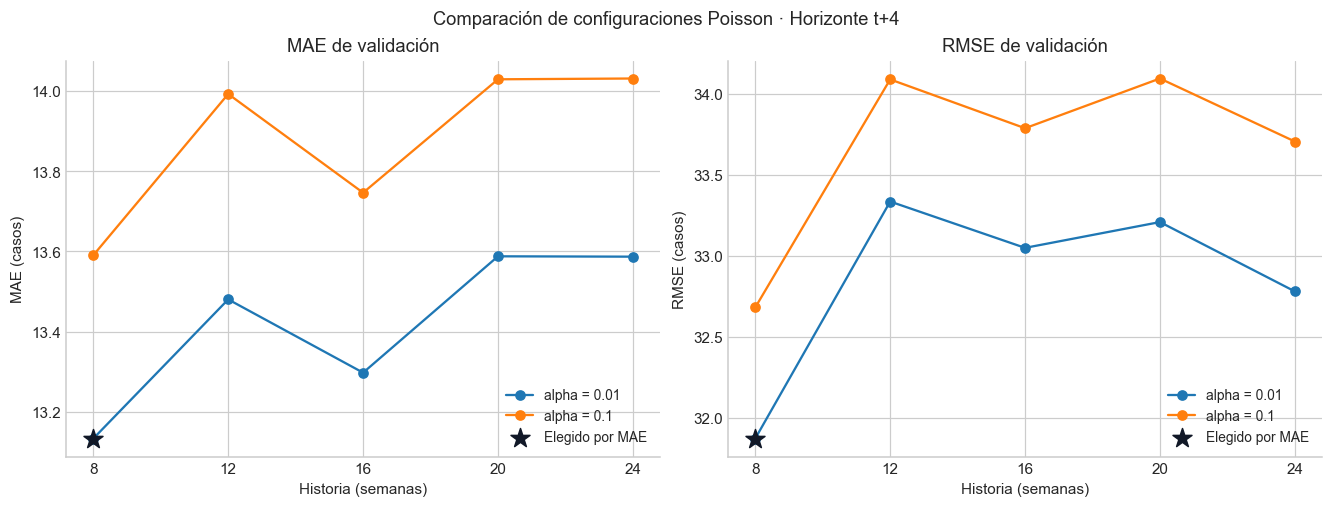

In [13]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for eje, metrica in zip(ejes, ['MAE', 'RMSE']):
    for alpha, grupo in ranking.groupby('ALPHA', sort=True):
        grupo = grupo.sort_values('HISTORIA')
        eje.plot(grupo['HISTORIA'], grupo[metrica], marker='o', label=f'alpha = {alpha}')
    eje.scatter([mejor['HISTORIA']], [mejor[metrica]], s=170, marker='*',
                color='#111827', zorder=5, label='Elegido por MAE')
    eje.set(title=f'{metrica} de validación', xlabel='Historia (semanas)',
            ylabel=f'{metrica} (casos)', xticks=list(HISTORIAS))
    eje.legend(fontsize=9)
fig.suptitle('Comparación de configuraciones Poisson · Horizonte t+4')
mostrar_figura(fig, '01_configuraciones_validacion')

## 5. Comparación global: validación frente a prueba

**MAE** es el error absoluto promedio. **RMSE** penaliza más los errores grandes.
**Sesgo medio = predicción − observado**: un valor negativo indica subestimación.
Se añaden media observada y MAE/media como contexto de escala. Este cociente no es
una exactitud porcentual ni MAPE. Los resultados agrupan todas las semanas y municipios.

,N,MAE,RMSE,SESGO_MEDIO,MEDIA_OBSERVADA,MAE_SOBRE_MEDIA,FRACCION_SUBESTIMACION
CONJUNTO,,,,,,,
Validación,505,13.1333,31.8724,-4.2870,45.2376,0.2903,0.4851
Prueba,510,31.7669,75.1493,3.7579,108.2843,0.2934,0.3039


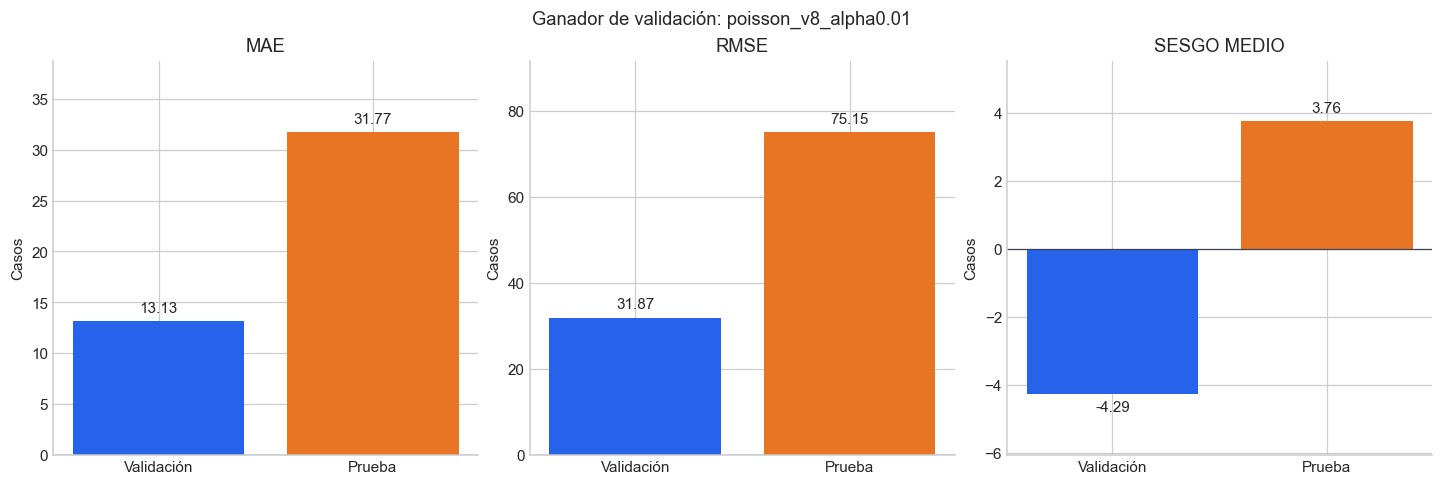

In [14]:
pred_val = pd.read_csv(SALIDA / 'predicciones_validacion.csv', dtype={'COD_DANE': 'string'},
                       parse_dates=['FECHA_OBJETIVO'])
pred_test = pd.read_csv(SALIDA / 'predicciones_prueba.csv', dtype={'COD_DANE': 'string'},
                        parse_dates=['FECHA_OBJETIVO'])
predicciones = pd.concat([
    pred_val.loc[pred_val['ID'].eq(seleccion)].assign(CONJUNTO='Validación'),
    pred_test.assign(CONJUNTO='Prueba'),
], ignore_index=True)
catalogo = desarrollo[int(mejor['HISTORIA'])]['validation']['meta'][
    ['COD_DANE', 'MUNICIPIO']].drop_duplicates()
predicciones = predicciones.merge(catalogo, on='COD_DANE', how='left', validate='many_to_one')
if predicciones['MUNICIPIO'].isna().any():
    raise ValueError('Predicciones sin nombre de municipio.')
predicciones['ERROR'] = predicciones['CASOS_PREDICHOS'] - predicciones['CASOS_ORIGINALES']
predicciones['ERROR_ABSOLUTO'] = predicciones['ERROR'].abs()

def resumir(grupo):
    real = grupo['CASOS_ORIGINALES'].to_numpy(float)
    estimado = grupo['CASOS_PREDICHOS'].to_numpy(float)
    mae = mean_absolute_error(real, estimado)
    media = float(np.mean(real))
    return {'N': len(grupo), 'MAE': mae,
            'RMSE': float(np.sqrt(mean_squared_error(real, estimado))),
            'SESGO_MEDIO': float(np.mean(estimado - real)),
            'MEDIA_OBSERVADA': media,
            'MAE_SOBRE_MEDIA': mae / media if media > 0 else np.nan,
            'FRACCION_SUBESTIMACION': float(np.mean(estimado < real))}

comparacion = pd.DataFrame([
    {'CONJUNTO': conjunto, **resumir(predicciones.loc[predicciones['CONJUNTO'].eq(conjunto)])}
    for conjunto in ORDEN_CONJUNTOS
]).set_index('CONJUNTO')
np.testing.assert_allclose(
    comparacion['MAE'],
    resultado_prueba.iloc[0][['MAE_VALIDATION', 'MAE_EVALUATION']].to_numpy(float),
    rtol=1e-8,
)
display(comparacion.round(4))
comparacion.to_csv(SALIDA / 'comparacion_validacion_prueba.csv', encoding='utf-8-sig')
predicciones.to_csv(SALIDA / 'predicciones_ganador_con_errores.csv', index=False, encoding='utf-8-sig')

fig, ejes = plt.subplots(1, 3, figsize=(13, 4.3), constrained_layout=True)
for eje, metrica in zip(ejes, ['MAE', 'RMSE', 'SESGO_MEDIO']):
    barras = eje.bar(ORDEN_CONJUNTOS, comparacion.loc[ORDEN_CONJUNTOS, metrica],
                    color=[COLORES[c] for c in ORDEN_CONJUNTOS])
    eje.bar_label(barras, fmt='%.2f', padding=4)
    eje.axhline(0, color='#374151', linewidth=0.8)
    eje.set(title=metrica.replace('_', ' '), ylabel='Casos')
    eje.margins(y=0.22)
fig.suptitle(f'Ganador de validación: {seleccion}')
mostrar_figura(fig, '02_validacion_vs_prueba')

## 6. Casos observados y predichos por municipio

Cada panel usa fechas objetivo t+4. La escala vertical se comparte entre validación
y prueba dentro de cada municipio y cambia entre municipios para permitir su lectura.
Las predicciones avanzan semana a semana con datos observados hasta cada emisión;
no son un pronóstico recursivo de dos años realizado desde una única fecha.

C:\Users\user\AppData\Local\Temp\ipykernel_10444\2881064432.py:32: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  figura.savefig(FIGURAS / f'{nombre}.png', dpi=160, bbox_inches='tight')


C:\Users\user\AppData\Local\Temp\ipykernel_10444\2881064432.py:33: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  figura.savefig(FIGURAS / f'{nombre}.svg', bbox_inches='tight')


C:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  fig.canvas.print_figure(bytes_io, **kw)


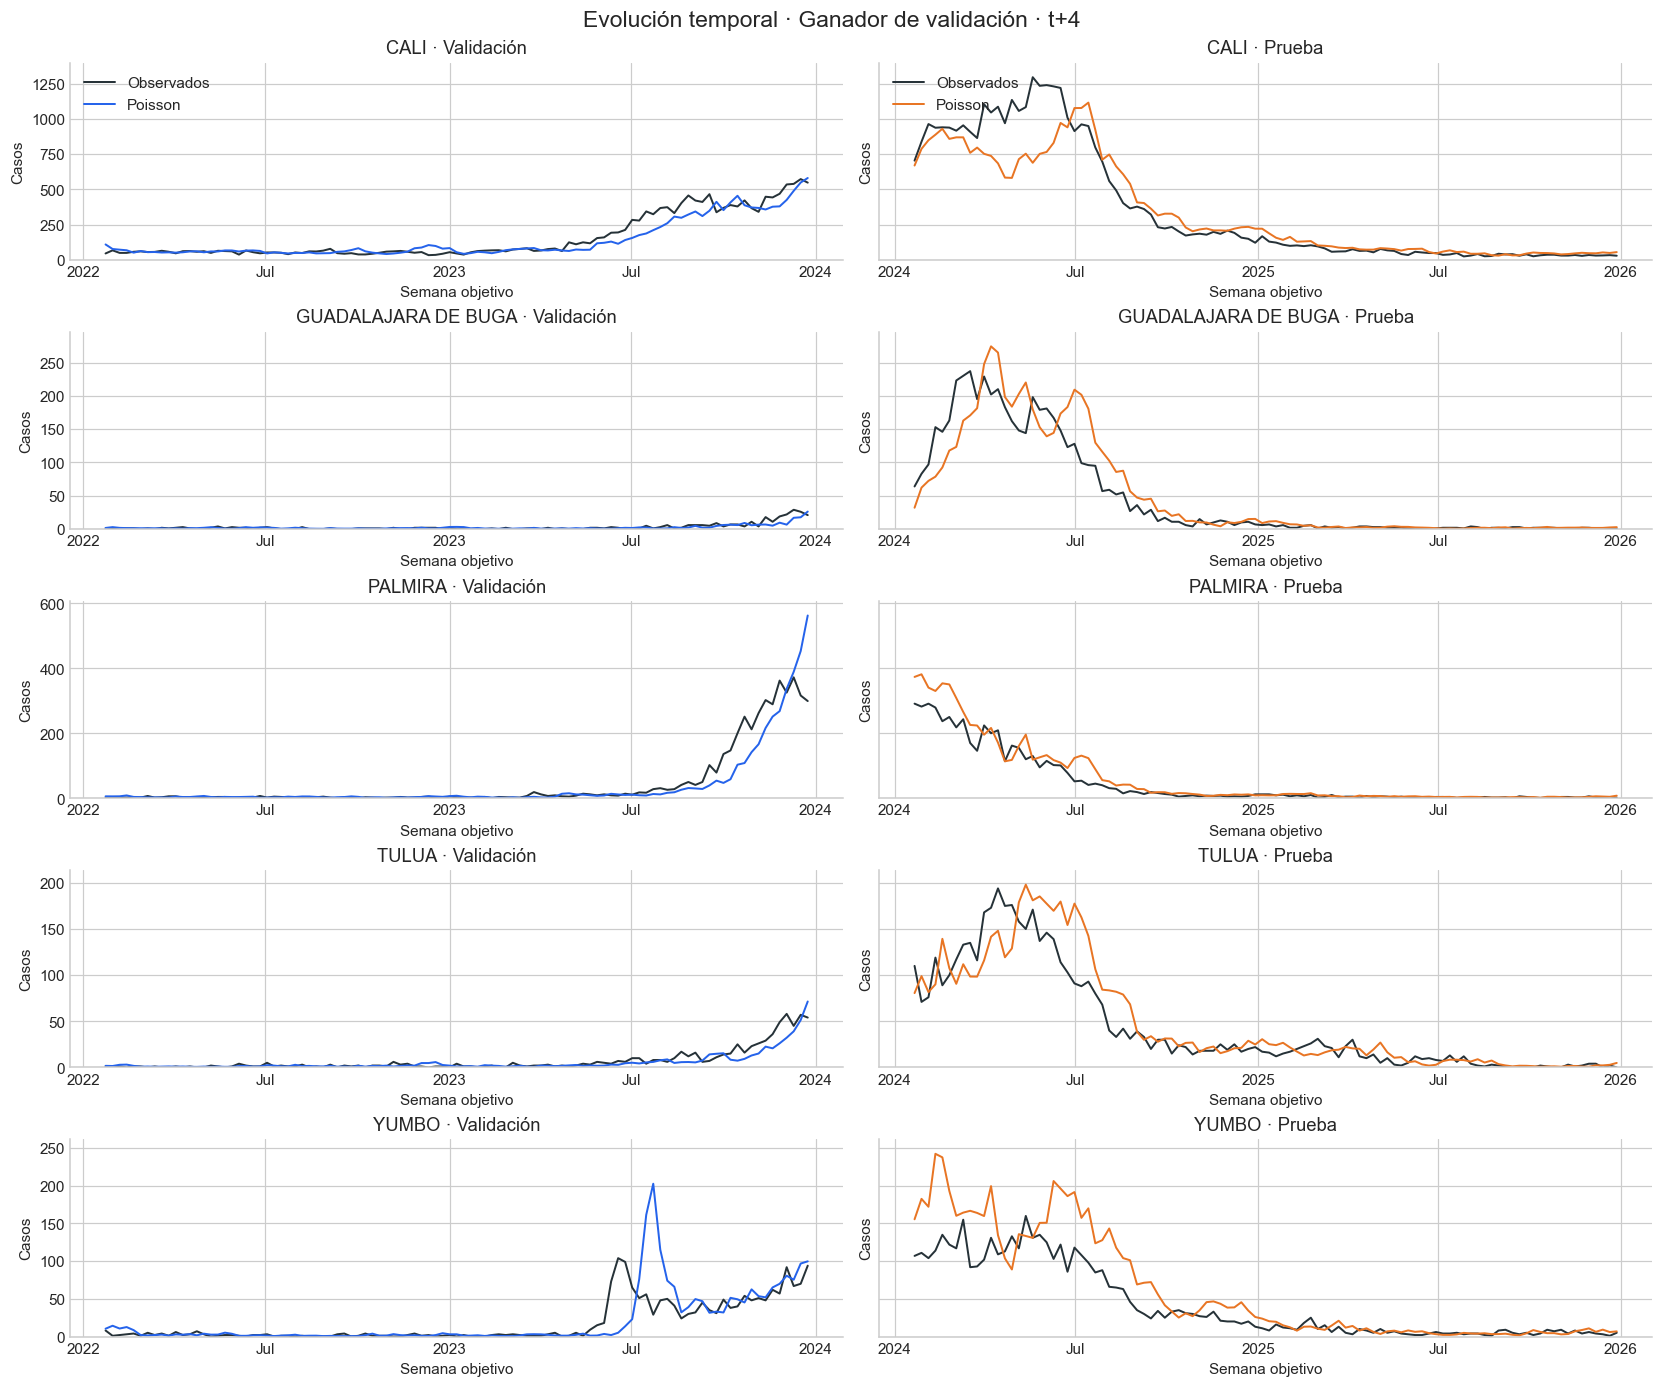

In [15]:
municipios = catalogo.sort_values('MUNICIPIO')['MUNICIPIO'].tolist()
fig, ejes = plt.subplots(len(municipios), 2, figsize=(15, 2.5 * len(municipios)),
                         squeeze=False, sharey='row', constrained_layout=True)
for i, municipio in enumerate(municipios):
    for j, conjunto in enumerate(ORDEN_CONJUNTOS):
        eje = ejes[i, j]
        grupo = predicciones.loc[
            predicciones['MUNICIPIO'].eq(municipio)
            & predicciones['CONJUNTO'].eq(conjunto)].sort_values('FECHA_OBJETIVO')
        eje.plot(grupo['FECHA_OBJETIVO'], grupo['CASOS_ORIGINALES'],
                 color='#263238', linewidth=1.3, label='Observados')
        eje.plot(grupo['FECHA_OBJETIVO'], grupo['CASOS_PREDICHOS'],
                 color=COLORES[conjunto], linewidth=1.3, label='Poisson')
        localizador = mdates.AutoDateLocator(minticks=3, maxticks=5)
        eje.xaxis.set_major_locator(localizador)
        eje.xaxis.set_major_formatter(mdates.ConciseDateFormatter(localizador))
        eje.set(title=f'{municipio} · {conjunto}', xlabel='Semana objetivo', ylabel='Casos')
        if i == 0:
            eje.legend(loc='upper left')
for i, municipio in enumerate(municipios):
    valores_municipio = predicciones.loc[predicciones['MUNICIPIO'].eq(municipio),
                                         ['CASOS_ORIGINALES', 'CASOS_PREDICHOS']]
    limite_municipio = max(1.0, float(valores_municipio.max().max())) * 1.08
    ejes[i, 0].set_ylim(0, limite_municipio)
fig.suptitle('Evolución temporal · Ganador de validación · t+4', fontsize=15)
mostrar_figura(fig, '03_series_por_municipio')

## 7. ¿En qué municipios se concentra el error?

Las métricas municipales evitan que el resumen global oculte comportamientos distintos.
Un municipio con más casos puede tener errores absolutos mayores; por eso la tabla
incluye también su media observada y MAE/media.

,CONJUNTO,COD_DANE,MUNICIPIO,N,MAE,RMSE,SESGO_MEDIO,MEDIA_OBSERVADA,MAE_SOBRE_MEDIA,FRACCION_SUBESTIMACION
0,Prueba,76001,CALI,102,87.7834,156.3349,-23.2491,359.0490,0.2445,0.2647
1,Prueba,76111,GUADALAJARA DE BUGA,102,17.0171,30.2110,4.4164,47.9412,0.3550,0.3627
2,Prueba,76520,PALMIRA,102,16.1712,31.0461,13.1510,48.3431,0.3345,0.2353
3,Prueba,76834,TULUA,102,15.3742,24.2497,5.1965,44.1373,0.3483,0.3824
4,Prueba,76892,YUMBO,102,22.4886,36.4944,19.2748,41.9510,0.5361,0.2745
5,Validación,76001,CALI,101,33.6721,50.7862,-16.3462,156.1782,0.2156,0.5743
6,Validación,76111,GUADALAJARA DE BUGA,101,1.8840,3.1443,-0.4716,3.0495,0.6178,0.4455
7,Validación,76520,PALMIRA,101,16.4345,41.4178,-5.4490,42.6832,0.3850,0.4851
8,Validación,76834,TULUA,101,3.0981,5.5827,-1.4821,6.9307,0.4470,0.5545
9,Validación,76892,YUMBO,101,10.5777,27.2676,2.3141,17.3465,0.6098,0.3663


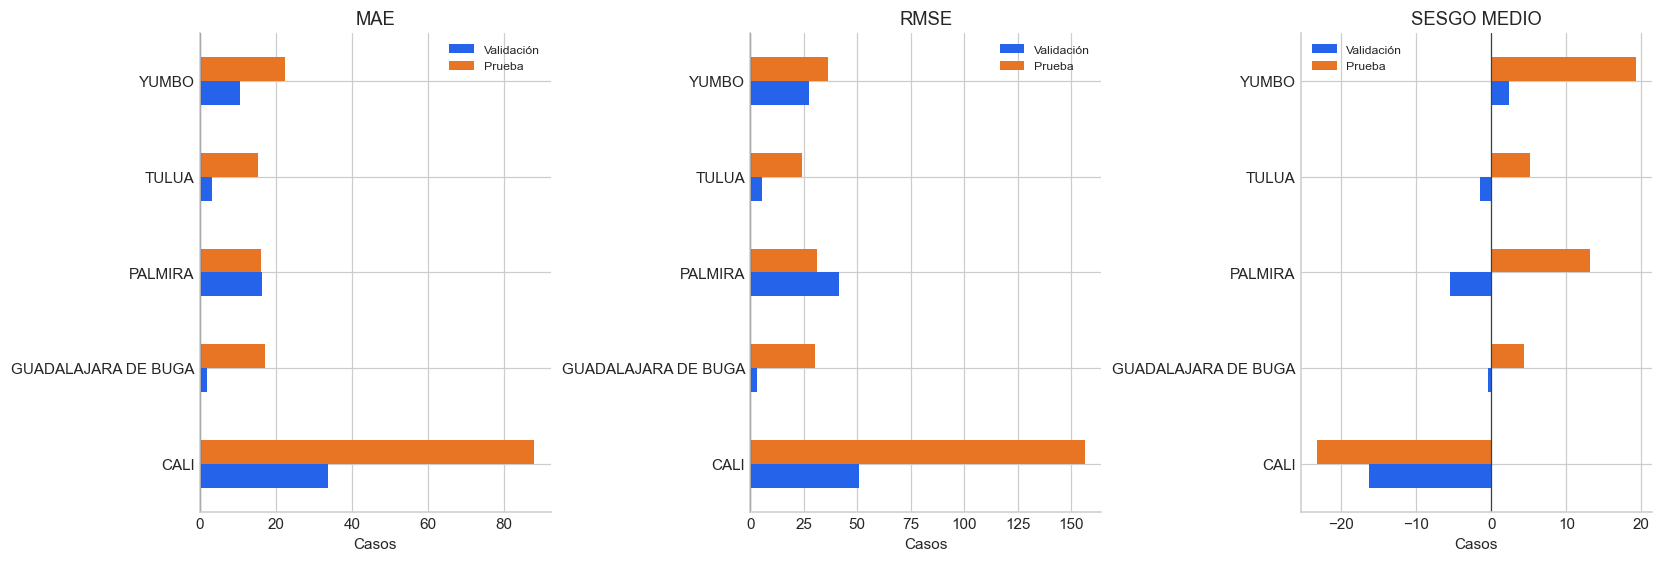

In [16]:
filas_municipales = []
for (conjunto, codigo, municipio), grupo in predicciones.groupby(
        ['CONJUNTO', 'COD_DANE', 'MUNICIPIO'], sort=True):
    filas_municipales.append({'CONJUNTO': conjunto, 'COD_DANE': codigo,
                             'MUNICIPIO': municipio, **resumir(grupo)})
metricas_municipales = pd.DataFrame(filas_municipales)
display(metricas_municipales.round(4))
metricas_municipales.to_csv(SALIDA / 'metricas_por_municipio.csv', index=False, encoding='utf-8-sig')
fig, ejes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
for eje, metrica in zip(ejes, ['MAE', 'RMSE', 'SESGO_MEDIO']):
    tabla = metricas_municipales.pivot(index='MUNICIPIO', columns='CONJUNTO', values=metrica)
    tabla.reindex(index=municipios, columns=ORDEN_CONJUNTOS).plot.barh(
        ax=eje, color=[COLORES[c] for c in ORDEN_CONJUNTOS])
    eje.axvline(0, color='#374151', linewidth=0.8)
    eje.set(title=metrica.replace('_', ' '), xlabel='Casos', ylabel='')
    eje.legend(fontsize=8)
mostrar_figura(fig, '04_metricas_por_municipio')

## 8. Diagnóstico de errores

En la dispersión, la diagonal indica predicción perfecta; puntos bajo ella representan
subestimación. El histograma usa error = predicho − observado. Estos gráficos describen
los errores; no constituyen intervalos de confianza ni una prueba formal de distribución.

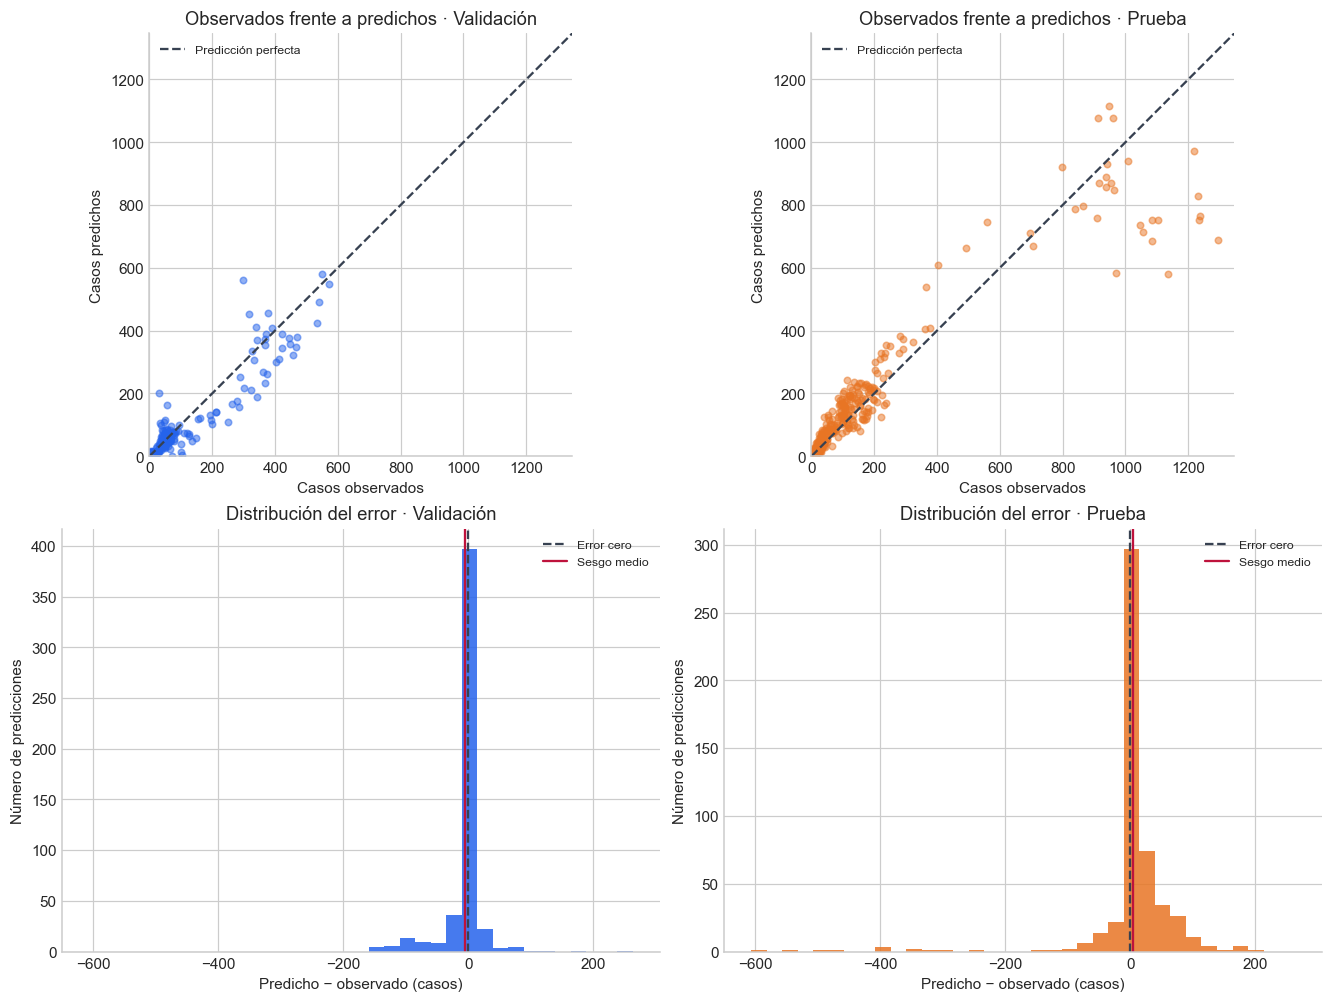

**Las diez predicciones con mayor error absoluto:**

,CONJUNTO,MUNICIPIO,FECHA_OBJETIVO,CASOS_ORIGINALES,CASOS_PREDICHOS,ERROR,ERROR_ABSOLUTO
522,Prueba,CALI,2024-05-19,1295,688.624,-606.376,606.376
519,Prueba,CALI,2024-04-28,1134,581.496,-552.504,552.504
523,Prueba,CALI,2024-05-26,1234,751.703,-482.297,482.297
524,Prueba,CALI,2024-06-02,1239,765.510,-473.490,473.490
517,Prueba,CALI,2024-04-14,1086,684.831,-401.169,401.169
525,Prueba,CALI,2024-06-09,1230,829.779,-400.221,400.221
518,Prueba,CALI,2024-04-21,969,583.676,-385.324,385.324
515,Prueba,CALI,2024-03-31,1103,752.121,-350.879,350.879
520,Prueba,CALI,2024-05-05,1056,714.144,-341.856,341.856
521,Prueba,CALI,2024-05-12,1083,753.169,-329.831,329.831


In [17]:
fig, ejes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
limite = max(1.0, float(predicciones[['CASOS_ORIGINALES', 'CASOS_PREDICHOS']].max().max())) * 1.04
bordes = np.histogram_bin_edges(predicciones['ERROR'], bins=35)
for j, conjunto in enumerate(ORDEN_CONJUNTOS):
    grupo = predicciones.loc[predicciones['CONJUNTO'].eq(conjunto)]
    eje = ejes[0, j]
    eje.scatter(grupo['CASOS_ORIGINALES'], grupo['CASOS_PREDICHOS'],
                color=COLORES[conjunto], s=18, alpha=0.5)
    eje.plot([0, limite], [0, limite], '--', color='#374151', label='Predicción perfecta')
    eje.set(title=f'Observados frente a predichos · {conjunto}',
            xlabel='Casos observados', ylabel='Casos predichos',
            xlim=(0, limite), ylim=(0, limite))
    eje.set_aspect('equal', adjustable='box')
    eje.legend(fontsize=8)
    eje = ejes[1, j]
    eje.hist(grupo['ERROR'], bins=bordes, color=COLORES[conjunto], alpha=0.85)
    eje.axvline(0, linestyle='--', color='#374151', label='Error cero')
    eje.axvline(grupo['ERROR'].mean(), color='#be123c', label='Sesgo medio')
    eje.set(title=f'Distribución del error · {conjunto}',
            xlabel='Predicho − observado (casos)', ylabel='Número de predicciones')
    eje.legend(fontsize=8)
mostrar_figura(fig, '05_diagnostico_errores')

mayores_errores = predicciones.nlargest(10, 'ERROR_ABSOLUTO')[[
    'CONJUNTO', 'MUNICIPIO', 'FECHA_OBJETIVO', 'CASOS_ORIGINALES',
    'CASOS_PREDICHOS', 'ERROR', 'ERROR_ABSOLUTO']]
display(Markdown('**Las diez predicciones con mayor error absoluto:**'))
display(mayores_errores.round(3))
mayores_errores.to_csv(SALIDA / 'mayores_errores.csv', index=False, encoding='utf-8-sig')

## 9. Poisson frente a los otros modelos del proyecto

Se reutilizan **métricas agregadas ya exportadas** en
`modelos/experimentos/metricas_tres_conjuntos.csv`, `evaluacion_prueba.csv` y
`ranking_validacion.csv`. Las redes y los otros modelos no se vuelven a entrenar aquí.
Las tablas externas tienen redondeo a tres decimales; Poisson conserva su precisión.

Se comprueba que los tamaños declarados sean 505 en validación y 510 en prueba.
La comparación es descriptiva: estas tablas no permiten comprobar que coincidan todas
las fechas y predicciones individuales, ni aislar efectos de versiones de librerías.
El test ya conocido **no se utiliza para escoger otra configuración**.
Si faltan las tablas externas, las secciones Poisson siguen siendo ejecutables.

,MODELO,MAE_VALIDATION,RMSE_VALIDATION,MAE_EVALUATION,RMSE_EVALUATION,N_VALIDACION,N_PRUEBA,ORIGEN
0,"LSTM 64 · Dense16 · D0,0 · 20s",11.377,26.837,38.139,95.413,505,510,Tablas exportadas del proyecto
1,LSTM local 16 · Dense8 (5 redes) · 24s,12.872,30.108,48.849,112.727,505,510,Tablas exportadas del proyecto
2,Poisson · 8s · alpha=0.01,13.133,31.872,31.767,75.149,505,510,Este notebook
3,XGBoost · 24s,14.759,36.342,40.596,95.975,505,510,Tablas exportadas del proyecto
4,Regresión lineal · 12s,14.841,36.872,31.285,78.708,505,510,Tablas exportadas del proyecto
5,Random Forest · 24s,14.857,36.810,43.465,104.825,505,510,Tablas exportadas del proyecto


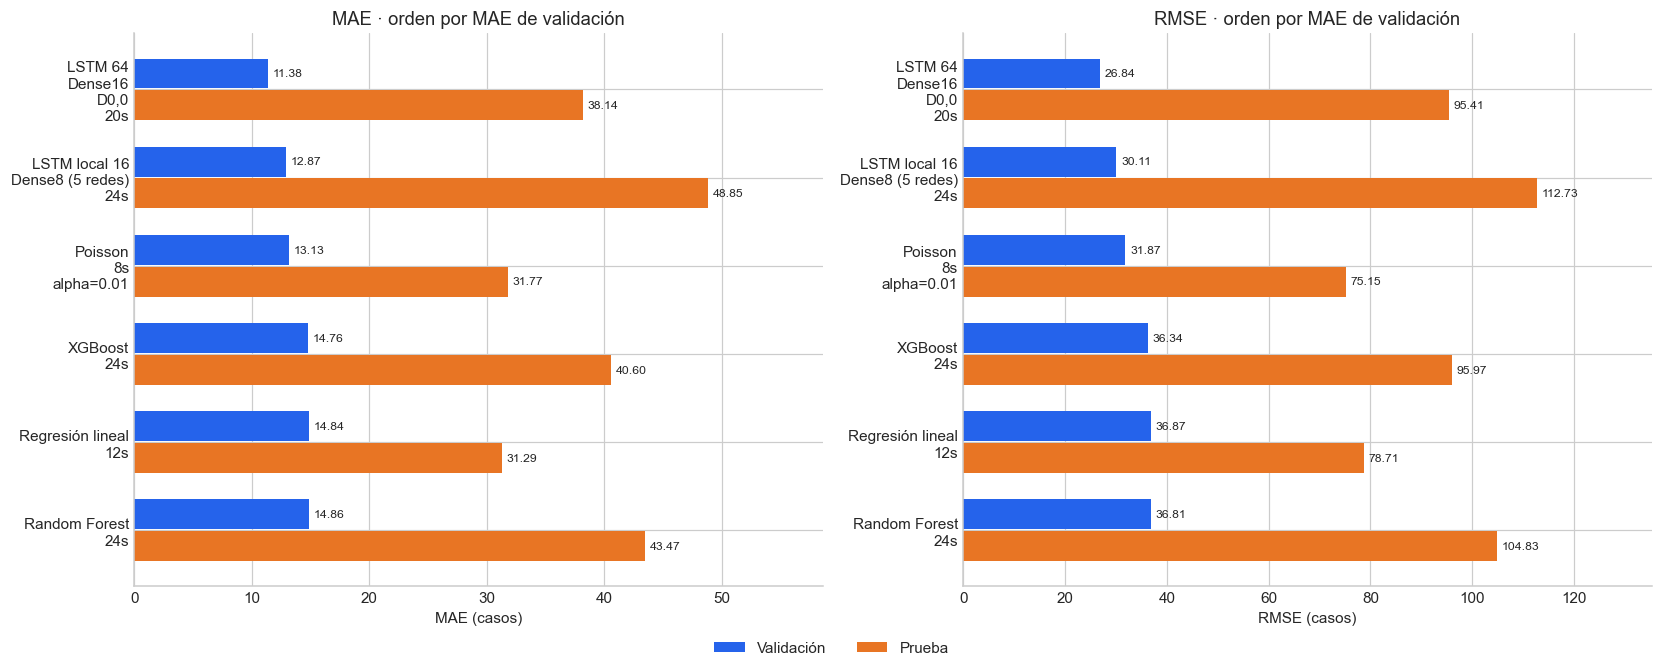

In [18]:
ruta_experimentos = RAIZ_PROYECTO / 'modelos/experimentos'
archivos_comparacion = [ruta_experimentos / nombre for nombre in [
    'metricas_tres_conjuntos.csv', 'evaluacion_prueba.csv', 'ranking_validacion.csv']]
comparacion_modelos = None
if all(p.is_file() for p in archivos_comparacion):
    externas = pd.read_csv(archivos_comparacion[0])
    evaluacion_externa = pd.read_csv(archivos_comparacion[1])
    ranking_externo = pd.read_csv(archivos_comparacion[2])
    columnas = ['MODELO', 'MAE_VALIDATION', 'RMSE_VALIDATION', 'MAE_EVALUATION', 'RMSE_EVALUATION']
    externas = externas[columnas].merge(
        evaluacion_externa[['MODELO', 'N']].rename(columns={'N': 'N_PRUEBA'}),
        on='MODELO', validate='one_to_one')
    externas = externas.merge(
        ranking_externo[['MODELO', 'N']].rename(columns={'N': 'N_VALIDACION'}),
        on='MODELO', validate='one_to_one')
    if not externas['N_PRUEBA'].eq(len(pred_test)).all() or not externas['N_VALIDACION'].eq(505).all():
        raise ValueError('Las métricas externas no tienen el mismo número de objetivos que Poisson.')
    fila_poisson = {'MODELO': f'Poisson · {int(mejor["HISTORIA"])}s · alpha={mejor["ALPHA"]}',
                   'MAE_VALIDATION': comparacion.loc['Validación', 'MAE'],
                   'RMSE_VALIDATION': comparacion.loc['Validación', 'RMSE'],
                   'MAE_EVALUATION': comparacion.loc['Prueba', 'MAE'],
                   'RMSE_EVALUATION': comparacion.loc['Prueba', 'RMSE'],
                   'N_VALIDACION': 505, 'N_PRUEBA': len(pred_test),
                   'ORIGEN': 'Este notebook'}
    comparacion_modelos = pd.concat([
        pd.DataFrame([fila_poisson]), externas.assign(ORIGEN='Tablas exportadas del proyecto')
    ], ignore_index=True).sort_values('MAE_VALIDATION').reset_index(drop=True)
    display(comparacion_modelos.round(3))
    comparacion_modelos.to_csv(SALIDA / 'comparacion_otros_modelos.csv', index=False, encoding='utf-8-sig')
    for archivo in archivos_comparacion:
        procedencia['sha256'][str(archivo.relative_to(RAIZ_PROYECTO))] = hashlib.sha256(archivo.read_bytes()).hexdigest()
    (SALIDA / 'procedencia.json').write_text(
        json.dumps(procedencia, indent=2, ensure_ascii=False), encoding='utf-8')

    fig, ejes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
    etiquetas = comparacion_modelos['MODELO'].str.replace(' · ', '\n', regex=False)
    posiciones = np.arange(len(comparacion_modelos))
    for eje, metrica in zip(ejes, ['MAE', 'RMSE']):
        for desplazamiento, conjunto, sufijo in [(-0.18, 'Validación', 'VALIDATION'),
                                                  (0.18, 'Prueba', 'EVALUATION')]:
            barras = eje.barh(posiciones + desplazamiento,
                             comparacion_modelos[f'{metrica}_{sufijo}'],
                             height=0.34, color=COLORES[conjunto], label=conjunto)
            eje.bar_label(barras, fmt='%.2f', padding=3, fontsize=8)
        eje.set(yticks=posiciones, yticklabels=etiquetas, xlabel=f'{metrica} (casos)',
                title=f'{metrica} · orden por MAE de validación')
        eje.invert_yaxis()
        eje.margins(x=0.2)
    fig.legend(*ejes[0].get_legend_handles_labels(), loc='outside lower center', ncol=2)
    mostrar_figura(fig, '06_comparacion_otros_modelos')
else:
    print('Comparación externa omitida; faltan:',
          ', '.join(p.name for p in archivos_comparacion if not p.is_file()))

## 10. Comparación e interpretación de esta ejecución

El texto siguiente se genera con las métricas calculadas, para que las conclusiones
se actualicen al ejecutar de nuevo. Los cambios entre periodos pueden reflejar diferencias
de escala o comportamiento de la serie; este experimento no identifica su causa.

In [19]:
val, test = comparacion.loc['Validación'], comparacion.loc['Prueba']
factor_mae = test['MAE'] / val['MAE'] if val['MAE'] > 0 else np.nan
factor_rmse = test['RMSE'] / val['RMSE'] if val['RMSE'] > 0 else np.nan
peor_municipio = metricas_municipales.loc[
    metricas_municipales['CONJUNTO'].eq('Prueba')].sort_values('MAE', ascending=False).iloc[0]
tendencia = 'subestimar' if test['SESGO_MEDIO'] < 0 else 'sobreestimar' if test['SESGO_MEDIO'] > 0 else 'no presentar sesgo medio'
dispersion = ranking['MAE'].max() - ranking['MAE'].min()
lectura = [
    f'**Configuración elegida:** {int(mejor["HISTORIA"])} semanas de historia y alpha={mejor["ALPHA"]}. '
    f'Convergieron {int(metricas["CONVERGIO"].sum())} de {len(metricas)} configuraciones.',
    f'**Cambio entre periodos:** el MAE pasa de {val["MAE"]:.2f} a {test["MAE"]:.2f} casos '
    f'({factor_mae:.2f} veces); el RMSE pasa de {val["RMSE"]:.2f} a {test["RMSE"]:.2f} '
    f'({factor_rmse:.2f} veces). Son periodos con casos medios de '
    f'{val["MEDIA_OBSERVADA"]:.2f} y {test["MEDIA_OBSERVADA"]:.2f}, respectivamente.',
    f'**Contexto de escala:** MAE/media observada pasa de '
    f'{100 * val["MAE_SOBRE_MEDIA"]:.2f}% a {100 * test["MAE_SOBRE_MEDIA"]:.2f}%. '
    'Este indicador permite contextualizar el aumento del error absoluto junto con '
    'el aumento del volumen de casos; no equivale a una exactitud porcentual.',
    f'**Sensibilidad a la configuración:** el MAE de los convergidos va de '
    f'{ranking["MAE"].min():.2f} a {ranking["MAE"].max():.2f} casos '
    f'(amplitud de {dispersion:.2f}). La mejor historia es {int(mejor["HISTORIA"])} semanas; '
    'tener más semanas disponibles no garantiza menor error.',
    f'**Sesgo en prueba:** {test["SESGO_MEDIO"]:.2f} casos. El modelo tiende a {tendencia}; '
    f'el {100 * test["FRACCION_SUBESTIMACION"]:.1f}% de las predicciones queda por debajo de lo observado.',
    f'**Errores grandes:** en prueba, RMSE={test["RMSE"]:.2f} supera MAE={test["MAE"]:.2f}. '
    'La tabla de mayores errores y las series permiten localizar las semanas responsables.',
    f'**Detalle municipal:** {peor_municipio["MUNICIPIO"]} presenta el mayor MAE absoluto de prueba '
    f'({peor_municipio["MAE"]:.2f} casos). Esta comparación debe leerse junto con su volumen de casos.',
]
if comparacion_modelos is not None:
    referencia_validacion = comparacion_modelos.loc[
        comparacion_modelos['ORIGEN'].ne('Este notebook')].sort_values('MAE_VALIDATION').iloc[0]
    lectura.append(
        f'**Frente al mejor modelo externo por validación:** '
        f'{referencia_validacion["MODELO"]} tiene MAE de validación '
        f'{referencia_validacion["MAE_VALIDATION"]:.2f} y MAE de prueba '
        f'{referencia_validacion["MAE_EVALUATION"]:.2f}; Poisson obtiene '
        f'{val["MAE"]:.2f} y {test["MAE"]:.2f}, respectivamente. '
        'Se comparan resultados de ejecuciones distintas, no un nuevo entrenamiento conjunto.')
    posicion_prueba = int((comparacion_modelos['MAE_EVALUATION'] < test['MAE']).sum()) + 1
    lectura.append(
        f'**Posición descriptiva en prueba:** Poisson ocupa el lugar {posicion_prueba} de '
        f'{len(comparacion_modelos)} por MAE. Esto no modifica la selección por validación '
        'ni demuestra superioridad estadística.')
lectura.append(
    '**Límites:** no se evalúan intervalos predictivos, significancia estadística ni '
    'sobredispersión. Las ventanas se solapan y el test ya era conocido. '
    'El error absoluto aceptable depende del uso del pronóstico y del volumen de casos.')
texto_conclusiones = '\n\n'.join(f'- {parrafo}' for parrafo in lectura)
display(Markdown(texto_conclusiones))
(SALIDA / 'interpretacion.txt').write_text(
    '\n\n'.join(lectura), encoding='utf-8')

- **Configuración elegida:** 8 semanas de historia y alpha=0.01. Convergieron 10 de 10 configuraciones.

- **Cambio entre periodos:** el MAE pasa de 13.13 a 31.77 casos (2.42 veces); el RMSE pasa de 31.87 a 75.15 (2.36 veces). Son periodos con casos medios de 45.24 y 108.28, respectivamente.

- **Contexto de escala:** MAE/media observada pasa de 29.03% a 29.34%. Este indicador permite contextualizar el aumento del error absoluto junto con el aumento del volumen de casos; no equivale a una exactitud porcentual.

- **Sensibilidad a la configuración:** el MAE de los convergidos va de 13.13 a 14.03 casos (amplitud de 0.90). La mejor historia es 8 semanas; tener más semanas disponibles no garantiza menor error.

- **Sesgo en prueba:** 3.76 casos. El modelo tiende a sobreestimar; el 30.4% de las predicciones queda por debajo de lo observado.

- **Errores grandes:** en prueba, RMSE=75.15 supera MAE=31.77. La tabla de mayores errores y las series permiten localizar las semanas responsables.

- **Detalle municipal:** CALI presenta el mayor MAE absoluto de prueba (87.78 casos). Esta comparación debe leerse junto con su volumen de casos.

- **Frente al mejor modelo externo por validación:** LSTM 64 · Dense16 · D0,0 · 20s tiene MAE de validación 11.38 y MAE de prueba 38.14; Poisson obtiene 13.13 y 31.77, respectivamente. Se comparan resultados de ejecuciones distintas, no un nuevo entrenamiento conjunto.

- **Posición descriptiva en prueba:** Poisson ocupa el lugar 2 de 6 por MAE. Esto no modifica la selección por validación ni demuestra superioridad estadística.

- **Límites:** no se evalúan intervalos predictivos, significancia estadística ni sobredispersión. Las ventanas se solapan y el test ya era conocido. El error absoluto aceptable depende del uso del pronóstico y del volumen de casos.

1791